In [1]:
import cv2
from matplotlib import pyplot as plt
import numpy as np

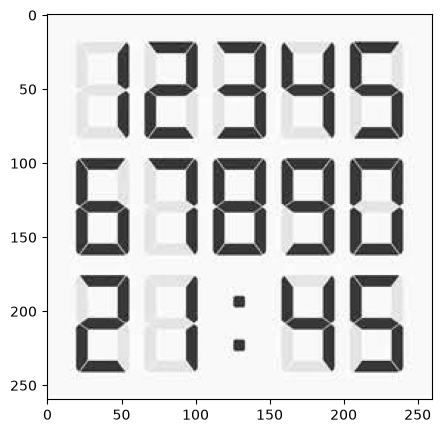

In [64]:
image_path = "/Users/alexey/Downloads/test_c.jpeg"

img = cv2.imread(image_path, cv2.IMREAD_COLOR_RGB)[:-20]
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(6,5))
plt.imshow(gray, "gray")
plt.show()

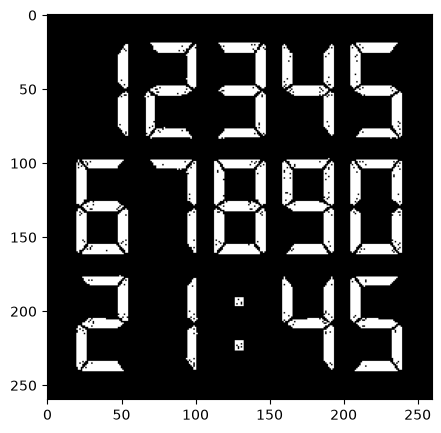

In [65]:
_, bin_img = cv2.threshold(gray, 100, 255, cv2.THRESH_BINARY)
bin_img = 255 - bin_img

plt.figure(figsize=(6,5))
plt.imshow(bin_img, "gray")
plt.show()

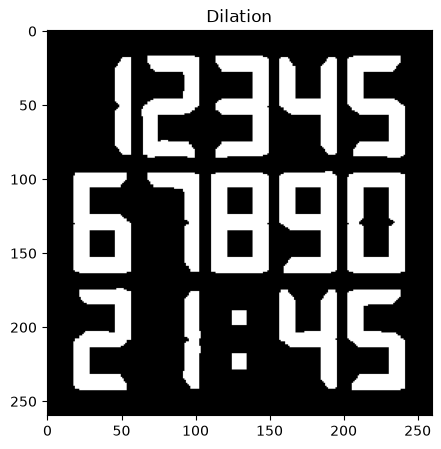

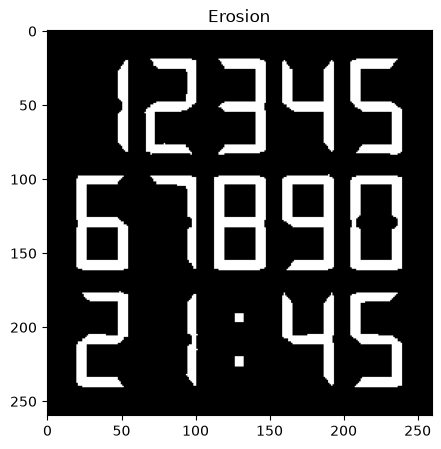

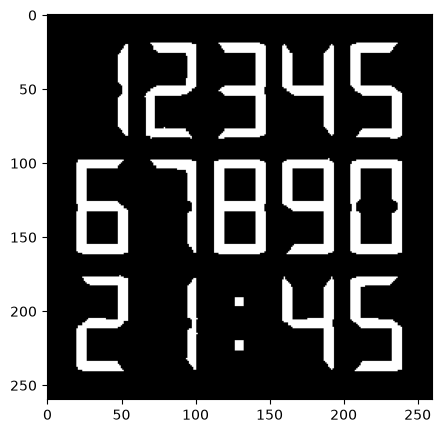

Count of submasks: 17
Skip mask 15
Skip mask 16


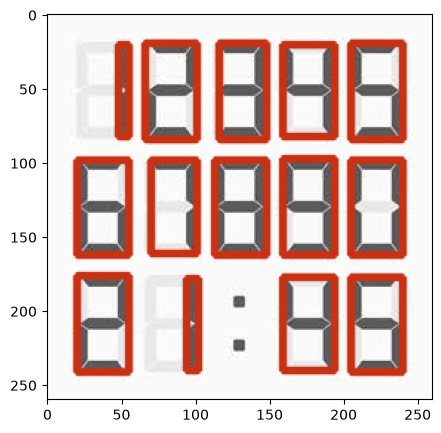

In [78]:
ek = np.ones((5, 5), dtype=np.uint8)

morph_img = cv2.morphologyEx(bin_img, cv2.MORPH_DILATE, ek)
plt.figure(figsize=(6,5))
plt.title("Dilation")
plt.imshow(morph_img, "gray")

morph_img = cv2.morphologyEx(morph_img, cv2.MORPH_ERODE, ek)
plt.figure(figsize=(6,5))
plt.title("Erosion")
plt.imshow(morph_img, "gray")

plt.figure(figsize=(6,5))
plt.imshow(morph_img, "gray")
plt.show()

count, masks = cv2.connectedComponents(morph_img)
print(f"Count of submasks: {count}")

vis = img.copy()

for mask_label in range(1, count):
    target_mask = masks == mask_label
    if target_mask.sum() < 50:
        print(f"Skip mask {mask_label}")
        continue

    x1, y1, w, h = cv2.boundingRect(target_mask.astype(np.uint8) * 255)
    x2 = x1 + w
    y2 = y1 + h
    vis = cv2.rectangle(vis, (x1, y1), (x2, y2), (200, 50, 20), 3, cv2.LINE_AA)
        
    # plt.figure(figsize=(4,4))
    # plt.imshow(target_mask, "gray")

    
plt.figure(figsize=(6,5))
plt.imshow(vis)
plt.show()

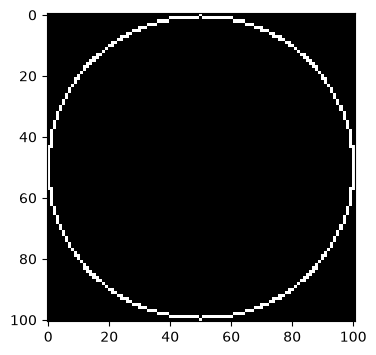

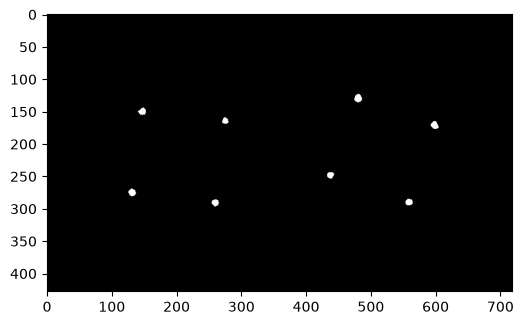

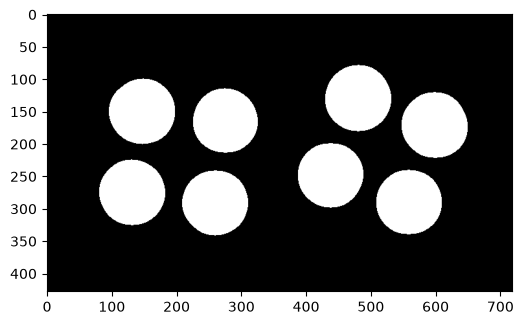

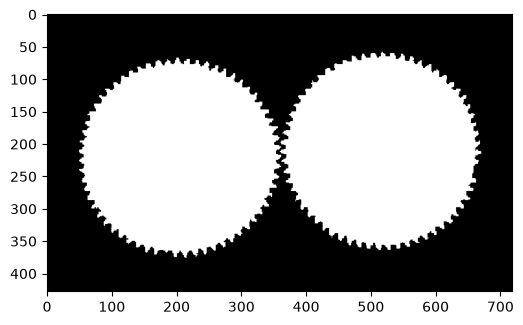

In [61]:
def make_ring(ksize: int, width: int) -> np.typing.NDArray:
    assert width % 2 == 0
    ek = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    inner_el = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize - width, ksize - width))
    inner_el = cv2.copyMakeBorder(inner_el, *(width // 2,)*4, borderType=cv2.BORDER_CONSTANT, value=0)
    return ek - inner_el

ek = make_ring(101, 2)

plt.figure(figsize=(4,4))
plt.imshow(ek, "gray")

morph_img = cv2.morphologyEx(bin_img, cv2.MORPH_ERODE, ek)
plt.figure(figsize=(6,5))
plt.imshow(morph_img, "gray")

ek = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (91, 91))
morph_img = cv2.morphologyEx(morph_img, cv2.MORPH_DILATE, ek)

plt.figure(figsize=(6,5))
plt.imshow(morph_img, "gray")

morph_img = cv2.bitwise_or(morph_img, bin_img)

plt.figure(figsize=(6,5))
plt.imshow(morph_img, "gray")

plt.show()